# OpenPOM — MPNN Exponential-Decay

# Imports & Paths

In [11]:
import ast, os, tempfile
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter("ignore", category=FutureWarning)

import deepchem as dc
from openpom.feat.graph_featurizer import GraphFeaturizer, GraphConvConstants
from openpom.utils.data_utils import get_class_imbalance_ratio
from openpom.models.mpnn_pom import MPNNPOMModel

from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score, f1_score, precision_score, recall_score

BASE_DIR = Path(__file__).resolve().parent if "__file__" in dir() else Path.cwd()
DATA_DIR = BASE_DIR / "data"
MODELS_DIR = BASE_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Load TASKS from dataset

In [12]:
_lists = (
    pd.read_csv(DATA_DIR / "Total_dataset_All_Food.csv", sep=";", header=0)["Labels"]
    .apply(ast.literal_eval)
)
TASKS = sorted(set(item for sublist in _lists for item in sublist))
print(f"No of tasks: {len(TASKS)}")

No of tasks: 120


# Build datasets

In [13]:
featurizer = GraphFeaturizer()

def load_semicolon_csv_dataset(csv_path, tasks, featurizer):

    df = pd.read_csv(csv_path, sep=';', header=0)
    ohe_matrix = np.array(
        df['OneHotEncoding'].apply(ast.literal_eval).tolist(), dtype=int
    )
    ohe_df = pd.DataFrame(ohe_matrix, columns=tasks)

    df = df.drop(columns=['OneHotEncoding']).reset_index(drop=True)
    df = pd.concat([df, ohe_df], axis=1)
    with tempfile.NamedTemporaryFile(mode='w', suffix='.csv',
                                     delete=False) as tmp:
        tmp_path = tmp.name
        df.to_csv(tmp_path, sep=',', index=False)
    try:
        loader = dc.data.CSVLoader(
            tasks=tasks,
            feature_field="SMILES",
            featurizer=featurizer,
        )
        dataset = loader.create_dataset(inputs=[tmp_path])
    finally:
        os.remove(tmp_path)
    return dataset

train_dataset = load_semicolon_csv_dataset(DATA_DIR / "OHE_train_dataset_All_Food.csv", TASKS, featurizer)
test_dataset  = load_semicolon_csv_dataset(DATA_DIR / "OHE_test_dataset_All_Food.csv",  TASKS, featurizer)

n_tasks = len(train_dataset.tasks)
print(f"train samples : {len(train_dataset)}")
print(f"test  samples : {len(test_dataset)}")
print(f"n_tasks : {n_tasks}")

train_ratios = get_class_imbalance_ratio(train_dataset)
assert len(train_ratios) == n_tasks

train samples : 1758
test  samples : 451
n_tasks : 120


# Train OpenPOM with Exponential Decay

In [ ]:
metric = dc.metrics.Metric(dc.metrics.f1_score)

best_f1 = -1.0
best_model_dir = None
best_cfg = {}
all_results = []

# Best LR = 0.005
# Best EPOCH = 50
LR_VALUES = [0.001, 0.005, 0.0001, 0.0005]
EPOCH_VALUES = [50, 100, 150, 200, 250]

for initial_rate in LR_VALUES:
    for nb_epoch in EPOCH_VALUES:

        run_name  = f"ExpoDecay_lr{initial_rate}_ep{nb_epoch}"
        model_dir = MODELS_DIR / run_name
        model_dir.mkdir(parents=True, exist_ok=True)

        learning_rate = dc.models.optimizers.ExponentialDecay(
            initial_rate=initial_rate,
            decay_rate=0.5,
            decay_steps=32 * 20,
            staircase=True,
        )

        model = MPNNPOMModel(
            n_tasks=n_tasks,
            batch_size=128,
            learning_rate=learning_rate,
            class_imbalance_ratio=train_ratios,
            loss_aggr_type="sum",
            node_out_feats=100,
            edge_hidden_feats=75,
            edge_out_feats=100,
            num_step_message_passing=5,
            mpnn_residual=True,
            message_aggregator_type="sum",
            mode="classification",
            number_atom_features=GraphConvConstants.ATOM_FDIM,
            number_bond_features=GraphConvConstants.BOND_FDIM,
            n_classes=1,
            readout_type="set2set",
            num_step_set2set=3,
            num_layer_set2set=2,
            ffn_hidden_list=[392, 392],
            ffn_embeddings=256,
            ffn_activation="relu",
            ffn_dropout_p=0.12,
            ffn_dropout_at_input_no_act=False,
            weight_decay=1e-5,
            self_loop=False,
            optimizer_name="adam",
            log_frequency=32,
            model_dir=str(model_dir),
            device_name="cuda",
        )

        start_time = datetime.now()
        for epoch in range(1, nb_epoch + 1):
            loss = model.fit(
                train_dataset,
                nb_epoch=1,
                max_checkpoints_to_keep=1,
                deterministic=False,
                restore=epoch > 1,
            )
            train_f1 = model.evaluate(train_dataset, [metric])["f1_score"]
            print(
                f"[{run_name}] epoch {epoch}/{nb_epoch} | "
                f"loss={loss:.4f} | train_f1={train_f1:.4f}"
            )

        elapsed = datetime.now() - start_time
        model.save_checkpoint()

        test_f1 = model.evaluate(test_dataset, [metric])["f1_score"]
        all_results.append((initial_rate, nb_epoch, test_f1))
        print(f">>> {run_name}  test_f1={test_f1:.4f}  time={elapsed}")

        if test_f1 > best_f1:
            best_f1        = test_f1
            best_model_dir = model_dir
            best_cfg       = {"lr": initial_rate, "epochs": nb_epoch}

print(f"\nBest config : {best_cfg}")
print(f"Best test F1: {best_f1:.4f}")
print(f"Saved at    : {best_model_dir}")

# Load Best Model for Evaluation

In [16]:
learning_rate_best = dc.models.optimizers.ExponentialDecay(
    initial_rate=best_cfg["lr"],
    decay_rate=0.5,
    decay_steps=32 * 20,
    staircase=True,
)

best_model = MPNNPOMModel(
    n_tasks=n_tasks,
    batch_size=128,
    learning_rate=learning_rate_best,
    class_imbalance_ratio=train_ratios,
    loss_aggr_type="sum",
    node_out_feats=100,
    edge_hidden_feats=75,
    edge_out_feats=100,
    num_step_message_passing=5,
    mpnn_residual=True,
    message_aggregator_type="sum",
    mode="classification",
    number_atom_features=GraphConvConstants.ATOM_FDIM,
    number_bond_features=GraphConvConstants.BOND_FDIM,
    n_classes=1,
    readout_type="set2set",
    num_step_set2set=3,
    num_layer_set2set=2,
    ffn_hidden_list=[392, 392],
    ffn_embeddings=256,
    ffn_activation="relu",
    ffn_dropout_p=0.12,
    ffn_dropout_at_input_no_act=False,
    weight_decay=1e-5,
    self_loop=False,
    optimizer_name="adam",
    log_frequency=32,
    model_dir=str(best_model_dir),
    device_name="cuda",
)

# Restore latest checkpoint from the best run directory
best_model.restore()

# Predict on test set
y_prob_raw = best_model.predict(test_dataset)
y_prob = y_prob_raw[:, :, 0] if y_prob_raw.ndim == 3 else y_prob_raw
y_pred = (y_prob >= 0.5).astype(int)
y_true = test_dataset.y

print(f"y_prob shape : {y_prob.shape}")
print(f"y_true shape : {y_true.shape}")

y_prob shape : (451, 120)
y_true shape : (451, 120)


# ROC and PR-curve

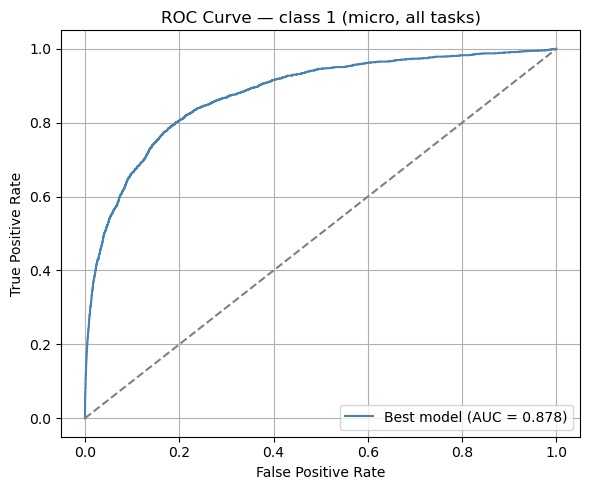

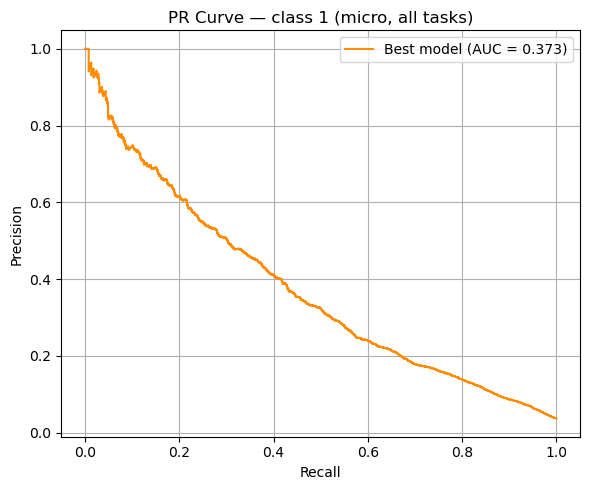

In [17]:
y_true_flat = y_true.flatten()
y_prob_flat = y_prob.flatten()
y_pred_flat = y_pred.flatten()

# ROC Curve
fpr, tpr, _ = roc_curve(y_true_flat, y_prob_flat)
roc_auc     = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Best model (AUC = {roc_auc:.3f})", color="steelblue")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — class 1 (micro, all tasks)")
plt.legend(loc="lower right")
plt.grid()
plt.tight_layout()
plt.show()

# PR curve
precision_curve, recall_curve, _ = precision_recall_curve(y_true_flat, y_prob_flat)
pr_auc = auc(recall_curve, precision_curve)

plt.figure(figsize=(6, 5))
plt.plot(recall_curve, precision_curve, label=f"Best model (AUC = {pr_auc:.3f})", color="darkorange")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR Curve — class 1 (micro, all tasks)")
plt.legend(loc="upper right")
plt.grid()
plt.tight_layout()
plt.show()

# Classification metrics summary

In [18]:
avg_type = "macro"

row = {
    "F1": round(f1_score(y_true_flat, y_pred_flat, average=avg_type, zero_division=0), 4),
    "Avg Precision": round(average_precision_score(y_true_flat, y_prob_flat, average=avg_type), 4),
    "Precision": round(precision_score(y_true_flat, y_pred_flat, average=avg_type, zero_division=0), 4),
    "Recall": round(recall_score(y_true_flat, y_pred_flat, average=avg_type, zero_division=0), 4),
}

print(f"{'':12} {'F1':>8} {'Avg Prec':>10} {'Precision':>11} {'Recall':>8}")
print("-" * 52)
print(f"{avg_type:<12} {row['F1']:>8.4f} {row['Avg Precision']:>10.4f} {row['Precision']:>11.4f} {row['Recall']:>8.4f}")

metrics_df = pd.DataFrame([row], index=[avg_type])
display(
    metrics_df.style
    .format("{:.4f}")
    .set_caption(f"Classification Metrics — Best model (lr={best_cfg['lr']}, epochs={best_cfg['epochs']})")
    .set_table_styles([{"selector": "caption", "props": [("font-size", "14px"), ("font-weight", "bold")]}])
    .background_gradient(cmap="YlGn", axis=0)
)

                   F1   Avg Prec   Precision   Recall
----------------------------------------------------
macro          0.6905     0.3728      0.6967   0.6848


,F1,Avg Precision,Precision,Recall
macro,0.6905,0.3728,0.6967,0.6848
